# Ablation: training on good poses only

Does keeping low-quality poses (and down-weighting them with the predicted pose-reliability score) add value beyond simply filtering them out? Two baselines are compared with the pose-aware model and the no-pose model:

| Model | Pose-quality task | Pose data (training / validation) | Activity data (training / validation) |
|---|---|---|---|
| **Pose-aware** | yes | RMSD ≤ 10 Å | predicted RMSD ≤ 10 Å |
| **No-pose** | no | – | predicted RMSD ≤ 10 Å |
| **Good only ≤ 2.5 Å** | yes | RMSD ≤ 2.5 Å | predicted RMSD ≤ 2.5 Å |
| **Pose data ≤ 2.5 Å** | yes | RMSD ≤ 2.5 Å | predicted RMSD ≤ 10 Å |

The activity complexes (Kinodata-3D) have no true RMSD to a crystal structure, only the RMSD predicted by the Kinodata-3D docking pipeline; the poses of the pose dataset (cross-docking) have the true RMSD to the crystal pose. "Good only" therefore filters the activity data by the predicted RMSD and the pose data by the true RMSD.

**Design.** Scaffold split, 5 folds, all other settings as for the pose-aware model. The RMSD restrictions apply to the training and validation data only; the test sets and the normalization of the activity values are those of the unrestricted split, so every model is evaluated on the same test complexes and the same test poses (checked below), and the comparisons are paired per fold. Activity values are in z-units (as the MAE of the paper).

**Data** (`data/ablation_good_poses/`): per model and fold, `test_activity.csv.gz` (predicted and true activity, predicted variance σ², predicted pose-reliability score q of each activity test complex) and, for the models with a pose-quality task, `test_pose.csv.gz` (predicted q and the q of the true RMSD of each test pose); `training_data.csv` holds the training and validation set sizes. Figures and tables are written to `output/`.

In [1]:
from pathlib import Path
import sys

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "ablation_good_poses"
OUTPUT = REPO / "analysis_publication" / "output" / "ablation_good_poses"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()

K_FOLDS = 5
K_SIG, X0_SIG = 0.9, 4.5     # q = 1 / (1 + exp(0.9 (RMSD - 4.5)))
GOOD_Q, BAD_Q = 0.8, 0.2     # q = 0.8 <-> 2.96 A, q = 0.2 <-> 6.04 A
CLASSES = ["good", "medium", "bad"]
Z90 = norm.ppf(0.95)
EPS = 0.10                   # floor of the activity-loss weight w = eps + (1 - eps) q

MODELS = {  # folder in DATA: (label, color, has a pose-quality task)
    "pose_aware":     ("Pose-aware", COLORS["pose_aware"], True),
    "no_pose":        ("No-pose", COLORS["no_pose"], False),
    "good_only_2.5A": ("Good only ≤ 2.5 Å", "tab:red", True),
    "pose_data_2.5A": ("Pose data ≤ 2.5 Å", "tab:purple", True),
}
ARMS = ["good_only_2.5A", "pose_data_2.5A"]
label = lambda m: MODELS[m][0]
color = lambda m: MODELS[m][1]


def rmsd_from_q(q):
    q = np.clip(np.asarray(q, dtype=float), 1e-7, 1 - 1e-7)
    return X0_SIG + np.log(1 / q - 1) / K_SIG


def pose_class(q):
    return np.select([np.asarray(q) >= GOOD_Q, np.asarray(q) <= BAD_Q], ["good", "bad"], "medium")


def auroc(score, positive):
    # P(score of a positive > score of a negative), ties counted half (Mann-Whitney)
    score, positive = np.asarray(score, dtype=float), np.asarray(positive, dtype=bool)
    n1 = positive.sum(); n0 = len(positive) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(score)
    return (r[positive].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def sigma_bins(d, n_bins=10):
    # 10 equal-count bins of sigma (as Fig. 7 of the paper): mean sigma and RMSE per bin
    s = d["sigma"].to_numpy(); sq = d["err"].to_numpy() ** 2
    b = np.clip(np.digitize(s, np.quantile(s, np.linspace(0, 1, n_bins + 1))[1:-1]), 0, n_bins - 1)
    t = pd.DataFrame({"b": b, "s": s, "sq": sq}).groupby("b").agg(n=("s", "size"), s=("s", "mean"), mse=("sq", "mean"))
    t["rmse"] = np.sqrt(t["mse"])
    return t


def ece(d, n_bins=10):
    # expected calibration error: sum_b (n_b / N) |RMSE_b - mean sigma_b|
    t = sigma_bins(d, n_bins)
    return float((t.n / t.n.sum() * (t.rmse - t.s).abs()).sum())

## Test predictions and checks

Every model must be evaluated on the same test complexes and poses (targets compared row by row, same order). The predicted pose class of each activity test complex is taken from the **pose-aware** model (good q ≥ 0.8, medium, bad q ≤ 0.2), the same classes for all models, so the per-class comparisons are paired.

In [2]:
test, test_pose = {}, {}
for m in MODELS:
    for k in range(K_FOLDS):
        d = pd.read_csv(DATA / m / f"fold_{k}" / "test_activity.csv.gz")
        d["fold"] = k
        d["sigma"] = np.sqrt(d["variance"])
        d["err"] = d["pred_activity"] - d["target_activity"]
        d["abs_err"] = d["err"].abs()
        test[m, k] = d
        f = DATA / m / f"fold_{k}" / "test_pose.csv.gz"
        if f.exists():
            p = pd.read_csv(f)
            p["fold"] = k
            p["rmsd"] = rmsd_from_q(p["target_pose"])
            test_pose[m, k] = p

for (m, k), d in test.items():
    r = test["pose_aware", k]
    assert len(d) == len(r) and np.allclose(d.target_activity, r.target_activity, atol=1e-5), f"{m} fold {k}: different activity test set"
    if (m, k) in test_pose:
        p, rp = test_pose[m, k], test_pose["pose_aware", k]
        assert len(p) == len(rp) and np.allclose(p.target_pose, rp.target_pose, atol=1e-5), f"{m} fold {k}: different pose test set"
    d["ref_class"] = pose_class(test["pose_aware", k]["pose"])
print("same activity test complexes and pose test poses in all models and folds: OK")
pd.DataFrame({"activity test complexes": [len(test["pose_aware", k]) for k in range(K_FOLDS)],
              "pose test poses": [len(test_pose["pose_aware", k]) for k in range(K_FOLDS)]},
             index=pd.Index(range(K_FOLDS), name="fold"))

same activity test complexes and pose test poses in all models and folds: OK


,activity test complexes,pose test poses
fold,,
0,12192,7040
1,12128,5792
2,11424,5312
3,12672,5632
4,11648,5472


### Training data

Training and validation set sizes per model (mean over the folds) and the largest RMSD in the training data (activity: predicted RMSD; pose: true RMSD). Filtering the activity data at 2.5 Å removes about two thirds of the activity complexes.

In [3]:
train = pd.read_csv(DATA / "training_data.csv")
summary_train = train.groupby("model", sort=False).mean(numeric_only=True).drop(columns="fold").round(1)
summary_train["activity training data vs pose-aware"] = (summary_train["n train activity"] / summary_train.loc["pose_aware", "n train activity"]).round(3)
summary_train.index = [label(m) for m in summary_train.index]
summary_train

,n train activity,n val activity,n train pose,n val pose,max predicted RMSD train activity (A),max true RMSD train pose (A),activity training data vs pose-aware
Pose-aware,95520.0,11833.6,47123.2,5900.8,10.0,10.0,1.000
No-pose,95520.0,11833.6,NaN,NaN,10.0,NaN,1.000
Good only ≤ 2.5 Å,35584.0,4422.4,18016.0,2086.4,2.5,2.5,0.373
Pose data ≤ 2.5 Å,95520.0,11833.6,18016.0,2086.4,10.0,2.5,1.000


## Activity test metrics

Per fold: MAE, RMSE, Pearson r; calibration: ECE (10 equal-count bins of σ) and the coverage of the 90 % interval μ ± 1.645 σ (ideal 0.90). Summary: mean ± sd over the folds, and the ECE with the five test folds pooled.

In [4]:
def act_metrics(d):
    cov90 = (d.abs_err <= Z90 * d.sigma).mean()
    return {"n": len(d), "MAE": d.abs_err.mean(), "RMSE": np.sqrt((d.err ** 2).mean()),
            "Pearson r": np.corrcoef(d.pred_activity, d.target_activity)[0, 1],
            "ECE": ece(d), "90% coverage": cov90, "|90% cov − 0.9|": abs(cov90 - 0.9), "mean σ": d.sigma.mean()}


per_fold = pd.DataFrame([{"model": m, "fold": k, **act_metrics(d)} for (m, k), d in test.items()])
per_fold.to_csv(OUTPUT / "activity_metrics_per_fold.csv", index=False)
pooled = {m: pd.concat([test[m, k] for k in range(K_FOLDS)], ignore_index=True) for m in MODELS}

METRICS = ["MAE", "RMSE", "Pearson r", "ECE", "90% coverage", "mean σ"]
agg = per_fold.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in METRICS})
summary["ECE pooled"] = [round(ece(pooled[m]), 3) for m in summary.index]
summary.index = [label(m) for m in summary.index]
summary.to_csv(OUTPUT / "activity_metrics_summary.csv")
summary

,MAE,RMSE,Pearson r,ECE,90% coverage,mean σ,ECE pooled
Pose-aware,0.589 ± 0.014,0.762 ± 0.018,0.646 ± 0.027,0.148 ± 0.037,0.816 ± 0.027,0.608 ± 0.033,0.146
No-pose,0.572 ± 0.015,0.745 ± 0.019,0.671 ± 0.019,0.179 ± 0.049,0.792 ± 0.040,0.556 ± 0.048,0.181
Good only ≤ 2.5 Å,0.699 ± 0.020,0.908 ± 0.027,0.475 ± 0.036,0.434 ± 0.030,0.626 ± 0.026,0.469 ± 0.036,0.434
Pose data ≤ 2.5 Å,0.568 ± 0.016,0.740 ± 0.019,0.675 ± 0.021,0.199 ± 0.032,0.779 ± 0.022,0.530 ± 0.019,0.200


### Paired differences per fold

Δ = model − reference on the same test complexes, against the pose-aware model and against the no-pose model: per-fold Δ, mean Δ with 95 % confidence interval (t distribution, 4 degrees of freedom), paired t-test, exact Wilcoxon signed-rank test (with 5 folds its smallest possible two-sided p is 0.0625), and the number of folds in which the model is better. With 5 folds the tests have little power; the per-fold signs are the more direct statement.

In [5]:
LOWER_BETTER = {"MAE": True, "RMSE": True, "Pearson r": False, "ECE": True, "|90% cov − 0.9|": True}


def paired_table(frame, base, models, metrics):
    rows = []
    b = frame[frame.model == base].set_index("fold")
    for m in models:
        if m == base:
            continue
        a = frame[frame.model == m].set_index("fold")
        folds = a.index.intersection(b.index)
        for c, lower in metrics.items():
            x, y = a.loc[folds, c].astype(float), b.loc[folds, c].astype(float)
            d = x - y
            n = len(d)
            half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
            better = (d < 0) if lower else (d > 0)
            rows.append({"model": label(m), "vs": label(base), "metric": c, "model mean": x.mean(), "reference mean": y.mean(),
                         **{f"Δ fold {k}": d.get(k, np.nan) for k in range(K_FOLDS)},
                         "mean Δ": d.mean(), "95% CI low": d.mean() - half, "95% CI high": d.mean() + half,
                         "paired t p": stats.ttest_rel(x, y).pvalue, "Wilcoxon p (exact)": stats.wilcoxon(x, y).pvalue,
                         "folds model better": f"{int(better.sum())}/{n}"})
    return pd.DataFrame(rows)


paired = pd.concat([paired_table(per_fold, "pose_aware", ["no_pose"] + ARMS, LOWER_BETTER),
                    paired_table(per_fold, "no_pose", ARMS, LOWER_BETTER)], ignore_index=True)
paired.to_csv(OUTPUT / "paired_differences.csv", index=False)
paired.round(3)

,model,vs,metric,model mean,reference mean,Δ fold 0,Δ fold 1,Δ fold 2,Δ fold 3,Δ fold 4,mean Δ,95% CI low,95% CI high,paired t p,Wilcoxon p (exact),folds model better
0,No-pose,Pose-aware,MAE,0.572,0.589,-0.019,-0.020,-0.021,-0.013,-0.010,-0.017,-0.023,-0.011,0.002,0.062,5/5
1,No-pose,Pose-aware,RMSE,0.745,0.762,-0.022,-0.023,-0.018,-0.006,-0.013,-0.016,-0.025,-0.008,0.006,0.062,5/5
2,No-pose,Pose-aware,Pearson r,0.671,0.646,0.035,0.032,0.026,0.017,0.013,0.025,0.013,0.037,0.005,0.062,5/5
3,No-pose,Pose-aware,ECE,0.179,0.148,-0.013,-0.001,0.100,0.108,-0.036,0.031,-0.052,0.115,0.357,0.812,3/5
4,No-pose,Pose-aware,|90% cov − 0.9|,0.108,0.084,-0.013,-0.004,0.079,0.085,-0.030,0.023,-0.044,0.091,0.391,0.812,3/5
5,Good only ≤ 2.5 Å,Pose-aware,MAE,0.699,0.589,0.112,0.087,0.104,0.122,0.125,0.110,0.091,0.129,0.000,0.062,0/5
6,Good only ≤ 2.5 Å,Pose-aware,RMSE,0.908,0.762,0.150,0.117,0.143,0.162,0.161,0.147,0.123,0.170,0.000,0.062,0/5
7,Good only ≤ 2.5 Å,Pose-aware,Pearson r,0.475,0.646,-0.192,-0.139,-0.171,-0.198,-0.157,-0.171,-0.202,-0.141,0.000,0.062,0/5
8,Good only ≤ 2.5 Å,Pose-aware,ECE,0.434,0.148,0.334,0.236,0.329,0.283,0.247,0.286,0.230,0.342,0.000,0.062,0/5
9,Good only ≤ 2.5 Å,Pose-aware,|90% cov − 0.9|,0.274,0.084,0.233,0.163,0.216,0.185,0.152,0.190,0.147,0.232,0.000,0.062,0/5


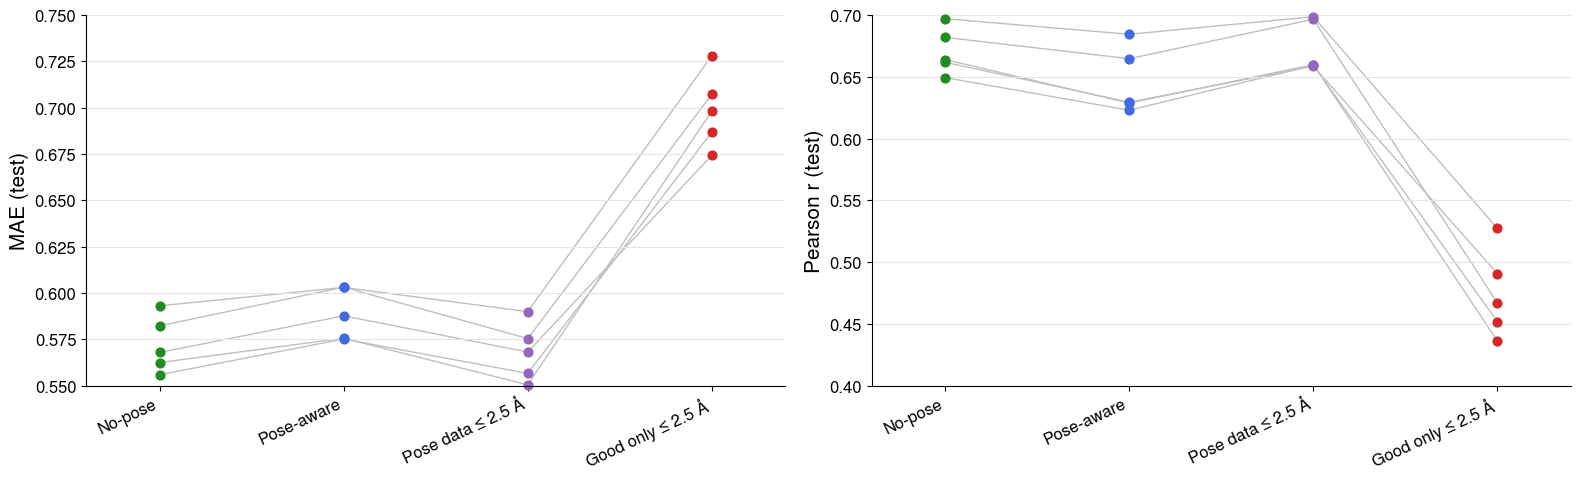

In [6]:
# per-fold values, one line per fold connecting the models (same test set)
ORDER = ["no_pose", "pose_aware", "pose_data_2.5A", "good_only_2.5A"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "Pearson r"]):
    g = per_fold.pivot(index="fold", columns="model", values=metric)[ORDER]
    x = np.arange(len(ORDER))
    for k, row in g.iterrows():
        ax.plot(x, row.values, "-", color="0.75", lw=1, zorder=1, clip_on=False)
    for i, m in enumerate(ORDER):
        ax.scatter(np.full(K_FOLDS, i), g[m], color=color(m), s=40, zorder=2, clip_on=False)
    ax.set(xticks=x, xlim=(-0.4, len(ORDER) - 0.6), ylabel=f"{metric} (test)")
    ax.set_xticklabels([label(m) for m in ORDER], rotation=25, ha="right")
    ax.grid(True, axis="y", color="0.9")
fig.tight_layout()
fig.savefig(OUTPUT / "per_fold_metrics.png", dpi=600)
plt.show()

## Calibration

Folds pooled; 10 equal-count bins of σ; RMSE against mean σ per bin, in z-units. Each panel compares one model with the pose-aware model.

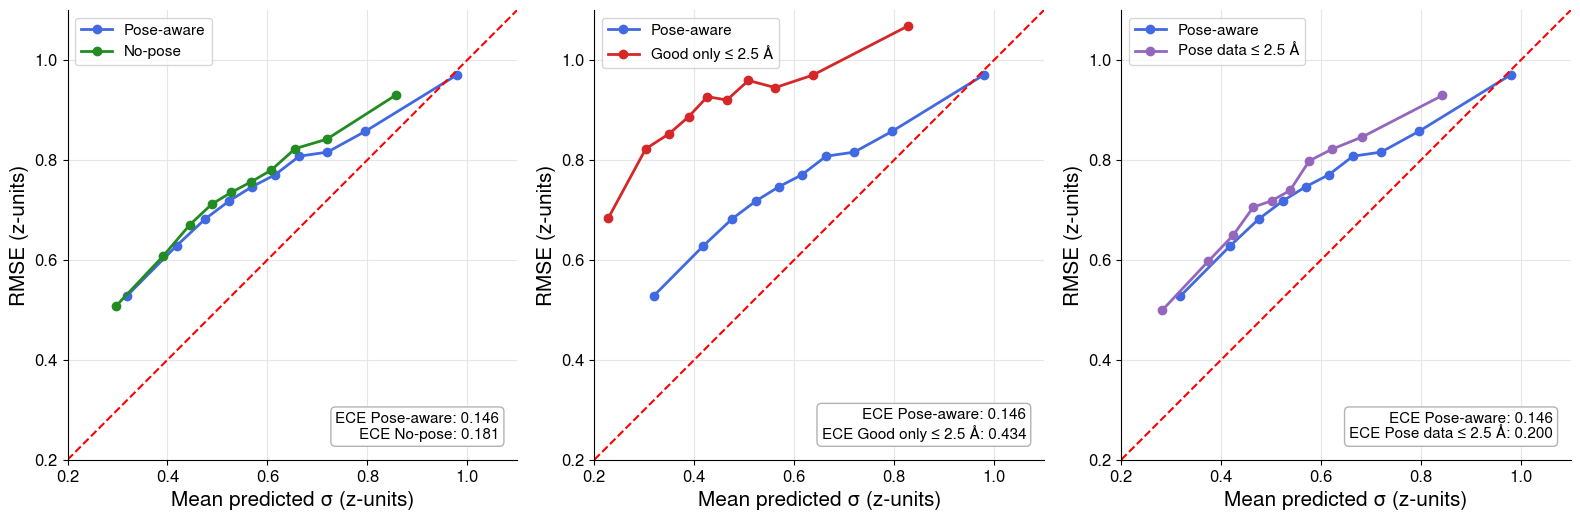

In [7]:
curves = {m: sigma_bins(pooled[m]) for m in MODELS}
vals = np.concatenate([np.r_[t.s, t.rmse] for t in curves.values()])
lo, hi = np.floor(vals.min() * 10) / 10, np.ceil(vals.max() * 10) / 10
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, m in zip(axes, ["no_pose"] + ARMS):
    for mm in ["pose_aware", m]:
        ax.plot(curves[mm].s, curves[mm].rmse, "o-", color=color(mm), label=label(mm))
    ax.plot([lo, hi], [lo, hi], "--", color=COLORS["diagonal"], lw=1.5)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Mean predicted σ (z-units)", ylabel="RMSE (z-units)")
    ax.set_aspect("equal")
    ax.grid(True, color="0.9")
    ax.legend(loc="upper left")
    ax.text(0.96, 0.04, f"ECE {label('pose_aware')}: {ece(pooled['pose_aware']):.3f}\nECE {label(m)}: {ece(pooled[m]):.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=11, bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.7"))
fig.tight_layout()
fig.savefig(OUTPUT / "calibration.png", dpi=600)
plt.show()

## Pose-quality prediction when trained on good poses only

A pose head trained only on poses with RMSD ≤ 2.5 Å sees only targets q ≥ 0.86. On the cross-docked test poses (true RMSD known), the mean predicted q per 0.5 Å bin of the true RMSD shows whether the head still separates good from bad poses; AUROC of q for good (≤ 2.96 Å) vs bad (≥ 6.04 Å) poses, per fold.

,Pearson r (q),AUROC q good vs bad,fraction predicted good,fraction predicted bad
model,,,,
Pose-aware,0.373 ± 0.073,0.730 ± 0.073,0.198 ± 0.093,0.176 ± 0.073
Good only ≤ 2.5 Å,0.081 ± 0.042,0.550 ± 0.022,1.000 ± 0.000,0.000 ± 0.000
Pose data ≤ 2.5 Å,0.085 ± 0.047,0.549 ± 0.032,1.000 ± 0.000,0.000 ± 0.000


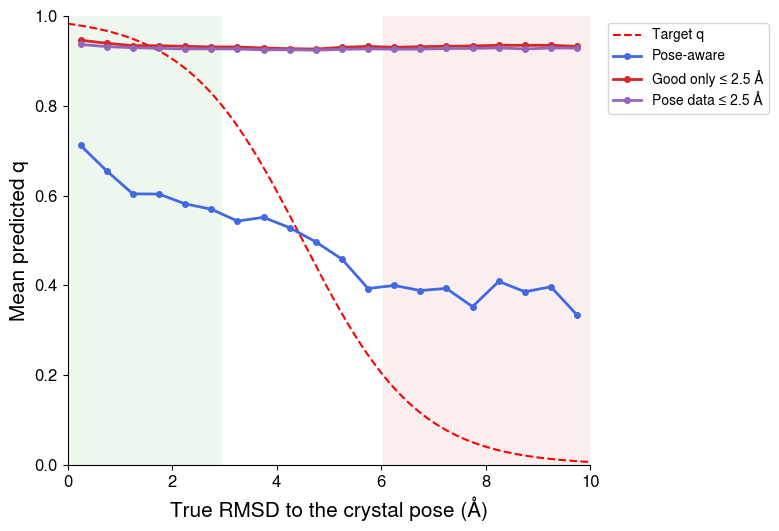

In [8]:
rows = []
for (m, k), p in test_pose.items():
    good, bad = (p.target_pose >= GOOD_Q).to_numpy(), (p.target_pose <= BAD_Q).to_numpy()
    sel = good | bad
    rows.append({"model": label(m), "fold": k, "Pearson r (q)": np.corrcoef(p.pred_pose, p.target_pose)[0, 1],
                 "AUROC q good vs bad": auroc(p.pred_pose.to_numpy()[sel], good[sel]),
                 "fraction predicted good": (p.pred_pose >= GOOD_Q).mean(), "fraction predicted bad": (p.pred_pose <= BAD_Q).mean()})
pose_fold = pd.DataFrame(rows)
PCOLS = ["Pearson r (q)", "AUROC q good vs bad", "fraction predicted good", "fraction predicted bad"]
agg = pose_fold.groupby("model", sort=False)[PCOLS].agg(["mean", "std"])
display(pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in PCOLS}))

bins = np.arange(0, 10.01, 0.5)
centers = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axvspan(0, 2.96, color=COLORS["good"], alpha=0.08, lw=0)
ax.axvspan(6.04, 10, color=COLORS["bad"], alpha=0.08, lw=0)
r = np.linspace(0, 10, 300)
ax.plot(r, 1 / (1 + np.exp(K_SIG * (r - X0_SIG))), "--", color=COLORS["diagonal"], lw=1.5, label="Target q")
for m in MODELS:
    if not MODELS[m][2]:
        continue
    p = pd.concat([test_pose[m, k] for k in range(K_FOLDS)])
    y = p.groupby(pd.cut(p.rmsd, bins), observed=False)["pred_pose"].mean().to_numpy()
    ax.plot(centers, y, "o-", ms=4, color=color(m), label=label(m))
ax.set(xlim=(0, 10), ylim=(0, 1), xlabel="True RMSD to the crystal pose (Å)", ylabel="Mean predicted q")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT / "pose_q_vs_true_rmsd.png", dpi=600)
plt.show()

### Consequence for the activity-loss weighting

The activity loss weights every complex by w = ε + (1 − ε) q (ε = 0.10), with q the model's own predicted score. On the activity test complexes: the share each model assigns to the good / medium / bad classes, the resulting weights, and the Kish effective sample size (Σw)² / (n Σw²) as a fraction of n (1 = uniform weighting).

In [9]:
rows = []
for m in MODELS:
    if not MODELS[m][2]:
        continue
    q = pooled[m]["pose"].to_numpy()
    w = EPS + (1 - EPS) * q
    rows.append({"model": label(m), **{f"own class {c}": (pose_class(q) == c).mean() for c in CLASSES},
                 "mean w": w.mean(), "fraction w < 0.5": (w < 0.5).mean(), "Kish n_eff / n": w.sum() ** 2 / (len(w) * (w ** 2).sum())})
pd.DataFrame(rows).set_index("model").round(3)

,own class good,own class medium,own class bad,mean w,fraction w < 0.5,Kish n_eff / n
model,,,,,,
Pose-aware,0.224,0.653,0.123,0.597,0.359,0.864
Good only ≤ 2.5 Å,1.000,0.000,0.000,0.936,0.000,1.000
Pose data ≤ 2.5 Å,1.000,0.000,0.000,0.931,0.000,1.000


## Does σ follow the predicted pose quality?

The predicted uncertainty of the pose-aware model is larger for complexes it predicts to have bad poses. AUROC of σ for bad vs good complexes (classes from the pose-aware model, the same complexes for all models; 0.5 = no separation) and the ratio of the mean σ of bad and good complexes, per fold.

In [10]:
rows = []
for (m, k), d in test.items():
    good, bad = d.loc[d.ref_class == "good", "sigma"].to_numpy(), d.loc[d.ref_class == "bad", "sigma"].to_numpy()
    rows.append({"model": m, "fold": k, "AUROC σ bad vs good": auroc(np.r_[good, bad], np.r_[np.zeros(len(good)), np.ones(len(bad))]),
                 "σ bad / σ good": bad.mean() / good.mean()})
sig_cls = pd.DataFrame(rows)
SCOLS = ["AUROC σ bad vs good", "σ bad / σ good"]
agg = sig_cls.groupby("model", sort=False)[SCOLS].agg(["mean", "std"])
display(pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in SCOLS}).rename(index=label))
paired_table(sig_cls, "pose_aware", list(MODELS), {"AUROC σ bad vs good": False})[
    ["model", "metric", "model mean", "reference mean", "mean Δ", "95% CI low", "95% CI high", "folds model better"]].round(3)

,AUROC σ bad vs good,σ bad / σ good
model,,
Pose-aware,0.787 ± 0.038,1.383 ± 0.052
No-pose,0.569 ± 0.047,1.068 ± 0.051
Good only ≤ 2.5 Å,0.548 ± 0.031,1.055 ± 0.034
Pose data ≤ 2.5 Å,0.570 ± 0.034,1.071 ± 0.036


,model,metric,model mean,reference mean,mean Δ,95% CI low,95% CI high,folds model better
0,No-pose,AUROC σ bad vs good,0.569,0.787,-0.219,-0.260,-0.177,0/5
1,Good only ≤ 2.5 Å,AUROC σ bad vs good,0.548,0.787,-0.239,-0.269,-0.209,0/5
2,Pose data ≤ 2.5 Å,AUROC σ bad vs good,0.570,0.787,-0.218,-0.234,-0.201,0/5


Distribution of σ per predicted pose class (classes from the pose-aware model, the same complexes for all models; folds pooled, kernel-density estimates). The AUROC of each model (mean ± sd over the folds, table above) is given in each panel.

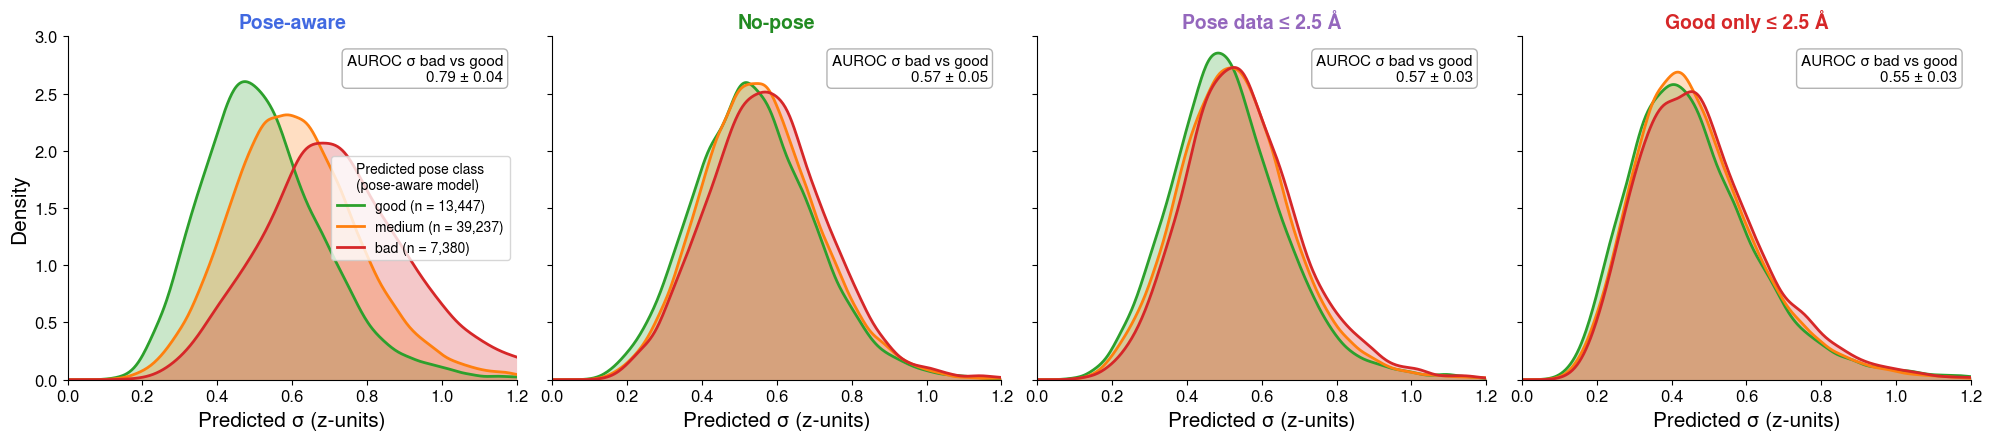

In [11]:
from scipy.stats import gaussian_kde

CLASS_COLORS = {"good": COLORS["good"], "medium": "tab:orange", "bad": COLORS["bad"]}
ORDER_SIGMA = ["pose_aware", "no_pose", "pose_data_2.5A", "good_only_2.5A"]
auroc_sigma = sig_cls.groupby("model")["AUROC σ bad vs good"].agg(["mean", "std"])
all_sigma = np.concatenate([pooled[m].sigma for m in ORDER_SIGMA])
x = np.linspace(0, np.ceil(np.quantile(all_sigma, 0.995) * 5) / 5, 400)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharex=True, sharey=True)
for ax, m in zip(axes, ORDER_SIGMA):
    d = pooled[m]
    for c in CLASSES:
        s = d.loc[d.ref_class == c, "sigma"].to_numpy()
        density = gaussian_kde(s)(x)
        ax.fill_between(x, density, color=CLASS_COLORS[c], alpha=0.25, lw=0)
        ax.plot(x, density, color=CLASS_COLORS[c], label=f"{c} (n = {len(s):,})")
    ax.set_title(label(m), color=color(m), fontweight="bold")
    ax.text(0.97, 0.95, f"AUROC σ bad vs good\n{auroc_sigma.loc[m, 'mean']:.2f} ± {auroc_sigma.loc[m, 'std']:.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=11, bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.7"))
    ax.set_xlabel("Predicted σ (z-units)")
axes[0].set_ylabel("Density")
axes[0].legend(title="Predicted pose class\n(pose-aware model)", loc="center right", fontsize=10, title_fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT / "sigma_per_pose_class.png", dpi=600)
plt.show()

### Accuracy and calibration per predicted pose class

MAE (mean over folds) and ECE (folds pooled) within the good / medium / bad classes of the pose-aware model.

In [12]:
rows = []
for c in CLASSES:
    for m in MODELS:
        g = pooled[m][pooled[m].ref_class == c]
        mae_folds = [test[m, k].loc[test[m, k].ref_class == c, "abs_err"].mean() for k in range(K_FOLDS)]
        rows.append({"class": c, "model": label(m), "n": len(g), "MAE": np.mean(mae_folds), "ECE pooled": ece(g)})
per_class = pd.DataFrame(rows)
per_class.to_csv(OUTPUT / "metrics_per_pose_class.csv", index=False)
per_class.pivot(index="model", columns="class", values=["MAE", "ECE pooled"]).reindex(columns=CLASSES, level=1).loc[[label(m) for m in MODELS]].round(3)

MAE               ECE pooled              
class               good medium    bad       good medium    bad
model                                                          
Pose-aware         0.560  0.591  0.632      0.197  0.140  0.096
No-pose            0.556  0.575  0.591      0.178  0.181  0.183
Good only ≤ 2.5 Å  0.661  0.702  0.753      0.401  0.437  0.475
Pose data ≤ 2.5 Å  0.547  0.570  0.597      0.196  0.199  0.209

Per fold: ECE within each predicted pose class, paired against the pose-aware model (same complexes in every model).

In [13]:
rows = []
for (m, k), d in test.items():
    for c in CLASSES:
        rows.append({"model": m, "fold": k, "class": c, "ECE": ece(d[d.ref_class == c])})
ece_cls = pd.DataFrame(rows)
ece_cls_paired = pd.concat([paired_table(ece_cls[ece_cls["class"] == c], "pose_aware", list(MODELS), {"ECE": True}).assign(**{"class": c})
                            for c in CLASSES], ignore_index=True)
ece_cls_paired.to_csv(OUTPUT / "ece_per_pose_class_paired.csv", index=False)
ece_cls_paired[["class", "model", "model mean", "reference mean"] + [f"Δ fold {k}" for k in range(K_FOLDS)] + ["mean Δ", "folds model better"]].round(3)

,class,model,model mean,reference mean,Δ fold 0,Δ fold 1,Δ fold 2,Δ fold 3,Δ fold 4,mean Δ,folds model better
0,good,No-pose,0.177,0.194,-0.053,-0.042,0.055,0.062,-0.108,-0.017,3/5
1,good,Good only ≤ 2.5 Å,0.399,0.194,0.238,0.172,0.236,0.226,0.153,0.205,0/5
2,good,Pose data ≤ 2.5 Å,0.194,0.194,-0.033,-0.019,0.043,0.041,-0.035,-0.000,3/5
3,medium,No-pose,0.180,0.143,-0.014,-0.005,0.107,0.119,-0.022,0.037,3/5
4,medium,Good only ≤ 2.5 Å,0.436,0.143,0.337,0.230,0.341,0.289,0.270,0.293,0/5
5,medium,Pose data ≤ 2.5 Å,0.199,0.143,0.027,0.016,0.094,0.085,0.058,0.056,0/5
6,bad,No-pose,0.184,0.111,0.048,0.047,0.137,0.116,0.017,0.073,0/5
7,bad,Good only ≤ 2.5 Å,0.475,0.111,0.436,0.323,0.427,0.337,0.299,0.364,0/5
8,bad,Pose data ≤ 2.5 Å,0.213,0.111,0.091,0.093,0.122,0.089,0.113,0.102,0/5
